In [1]:
pip install mysql-connector

Note: you may need to restart the kernel to use updated packages.


In [2]:
import mysql.connector

In [3]:
import mysql.connector
print("mysql connector is working")

mysql connector is working


In [4]:
pip install --upgrade mysql-connector-python

Note: you may need to restart the kernel to use updated packages.


In [5]:
import mysql.connector
data = mysql.connector.connect(
     host="localhost",
     user="root",
     password="root",
     database="fashion_trends_db"
)

In [6]:
cursor = data.cursor()
print("Cursor created successfully!")

Cursor created successfully!


In [ ]:
# Execute query
cursor.execute(query)

# Fetch SQL results
result = cursor.fetchall()

# Get column names
columns = [col[0] for col in cursor.description]

# Create DataFrame
df = pd.DataFrame(result, columns=columns)

# Check the data
print(df.head())

   Category  Total_Products
0    Shirts              10
1     Jeans              10
2  T-Shirts              10
3   Dresses              10
4     Shoes              10


In [16]:
query = """
SELECT *
FROM products
"""
cursor.execute(query)
results = cursor.fetchall()
for row in results:
    print(row)

(1, 'Classic Shirt', 'Shirts', 'UrbanStyle', 'Men', Decimal('499.00'), 25)
(2, 'Slim Jeans', 'Jeans', 'TrendWear', 'Women', Decimal('799.00'), 40)
(3, 'Cotton Tee', 'T-Shirts', 'FashionHub', 'Unisex', Decimal('999.00'), 35)
(4, 'Floral Dress', 'Dresses', 'StylePro', 'Women', Decimal('1299.00'), 20)
(5, 'Running Shoes', 'Shoes', 'NovaWear', 'Men', Decimal('1599.00'), 30)
(6, 'Denim Jacket', 'Jackets', 'UrbanStyle', 'Men', Decimal('1999.00'), 18)
(7, 'Mini Skirt', 'Skirts', 'TrendWear', 'Women', Decimal('2499.00'), 22)
(8, 'Formal Trousers', 'Trousers', 'FashionHub', 'Men', Decimal('2999.00'), 15)
(9, 'Winter Hoodie', 'Hoodies', 'StylePro', 'Unisex', Decimal('3499.00'), 28)
(10, 'Fashion Belt', 'Accessories', 'NovaWear', 'Men', Decimal('3999.00'), 32)
(11, 'Casual Shirt', 'Shirts', 'TrendWear', 'Men', Decimal('599.00'), 45)
(12, 'Straight Jeans', 'Jeans', 'FashionHub', 'Women', Decimal('899.00'), 30)
(13, 'Printed Tee', 'T-Shirts', 'StylePro', 'Unisex', Decimal('699.00'), 50)
(14, 'Party

In [9]:
query = """
SELECT *
FROM sales
"""
cursor.execute(query)
results = cursor.fetchall()
for row in results:
    print(row)

(1, 1, datetime.date(2025, 1, 1), 4, Decimal('5.00'), 'UPI', Decimal('4.0'))
(2, 2, datetime.date(2025, 1, 2), 2, Decimal('10.00'), 'Cash', Decimal('4.5'))
(3, 3, datetime.date(2025, 1, 3), 5, Decimal('15.00'), 'Credit Card', Decimal('4.2'))
(4, 4, datetime.date(2025, 1, 4), 3, Decimal('20.00'), 'Debit Card', Decimal('5.0'))
(5, 5, datetime.date(2025, 1, 5), 6, Decimal('0.00'), 'Net Banking', Decimal('3.5'))
(6, 6, datetime.date(2025, 1, 6), 2, Decimal('25.00'), 'UPI', Decimal('4.8'))
(7, 7, datetime.date(2025, 1, 7), 7, Decimal('30.00'), 'Cash', Decimal('4.0'))
(8, 8, datetime.date(2025, 1, 8), 1, Decimal('5.00'), 'Credit Card', Decimal('4.5'))
(9, 9, datetime.date(2025, 1, 9), 3, Decimal('10.00'), 'Debit Card', Decimal('4.2'))
(10, 10, datetime.date(2025, 1, 10), 4, Decimal('15.00'), 'Net Banking', Decimal('5.0'))
(11, 11, datetime.date(2025, 1, 11), 5, Decimal('20.00'), 'UPI', Decimal('3.5'))
(12, 12, datetime.date(2025, 1, 12), 2, Decimal('0.00'), 'Cash', Decimal('4.8'))
(13, 13, d

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

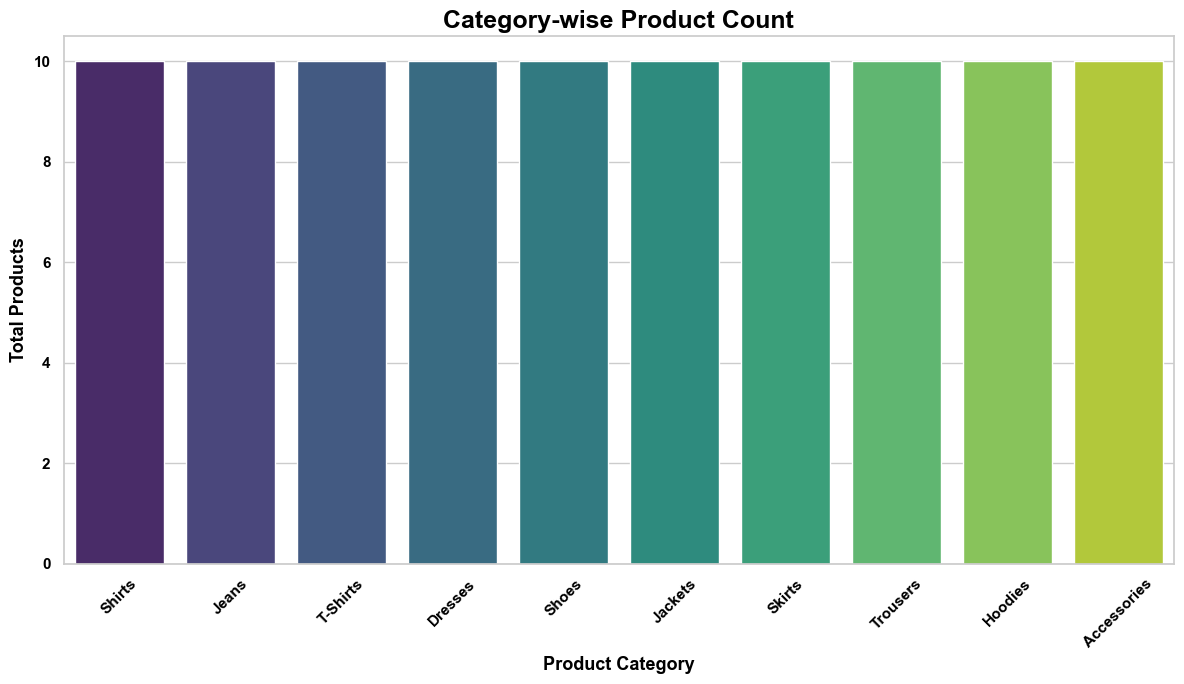

In [34]:
# barplot 

query = """
SELECT Category, COUNT(*) AS Total_Products
FROM Products
GROUP BY Category
ORDER BY Total_Products DESC
"""

cursor.execute(query)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df = pd.DataFrame(result, columns=columns)

plt.figure(figsize=(12, 7))
ax = sns.barplot(
    data=df, x="Category", y="Total_Products",
    hue="Category", palette="viridis", legend=False
)

ax.set_title("Category-wise Product Count",
             fontsize=18, fontweight="bold", color="black")
ax.set_xlabel("Product Category",
              fontsize=13, fontweight="bold", color="black")
ax.set_ylabel("Total Products",
              fontsize=13, fontweight="bold", color="black")
ax.tick_params(axis="both", colors="black")

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


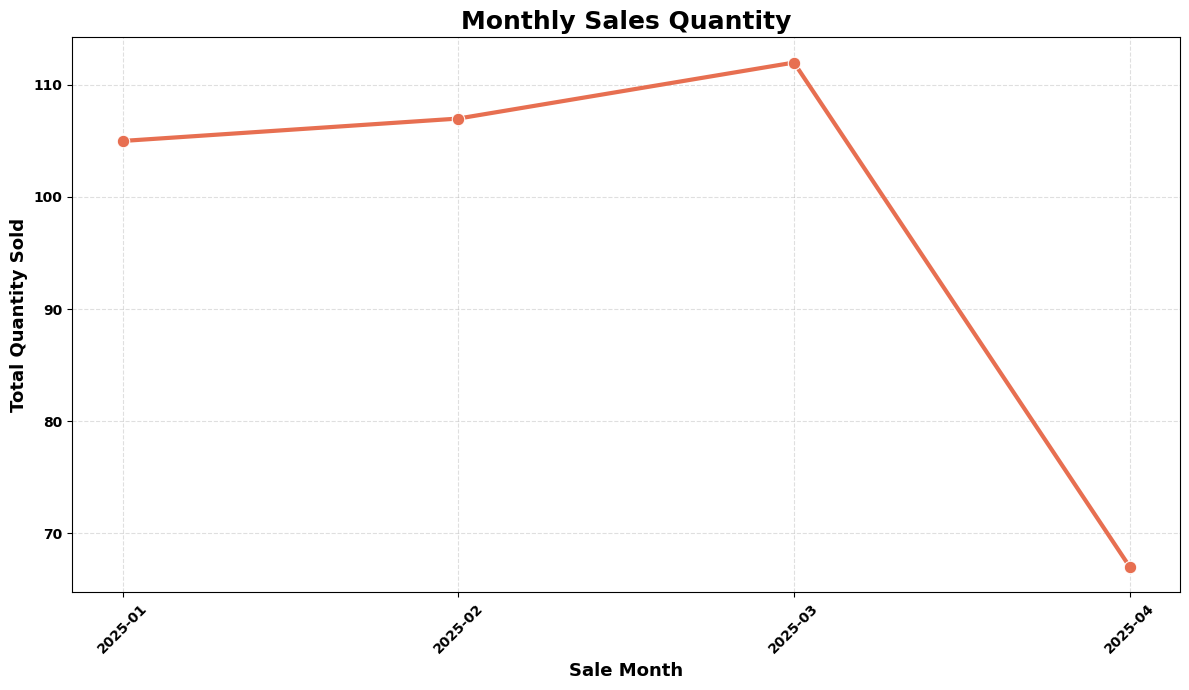

In [ ]:
# line plot
query = """
SELECT DATE_FORMAT(Sale_Date, '%Y-%m') AS Sale_Month,
       SUM(Quantity_Sold) AS Total_Quantity
FROM Sales
GROUP BY DATE_FORMAT(Sale_Date, '%Y-%m')
ORDER BY Sale_Month
"""

cursor.execute(query)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df = pd.DataFrame(result, columns=columns)

plt.figure(figsize=(12, 7))
ax = sns.lineplot(
    data=df, x="Sale_Month", y="Total_Quantity",
    marker="o", markersize=9, linewidth=3,
    color="#E76F51"
)

ax.set_title("Monthly Sales Quantity",
             fontsize=18, fontweight="bold", color="black")
ax.set_xlabel("Sale Month",
              fontsize=13, fontweight="bold", color="black")
ax.set_ylabel("Total Quantity Sold",
              fontsize=13, fontweight="bold", color="black")
ax.tick_params(axis="both", colors="black")

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


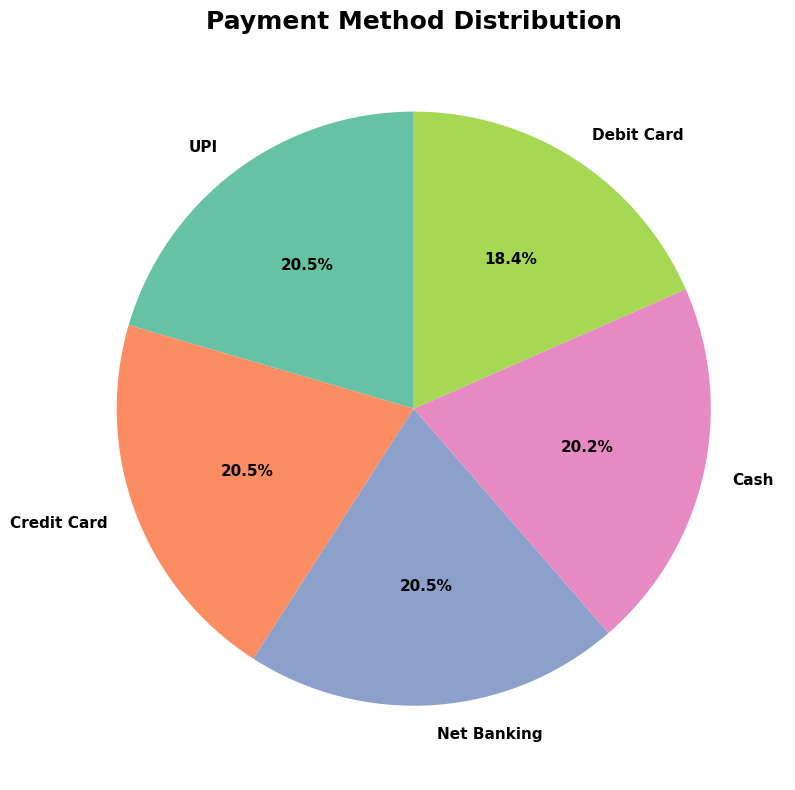

In [ ]:
# pie chart

query = """
SELECT Payment_Method,
       SUM(Quantity_Sold) AS Total_Quantity
FROM Sales
GROUP BY Payment_Method
ORDER BY Total_Quantity DESC
"""

cursor.execute(query)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df = pd.DataFrame(result, columns=columns)

fig, ax = plt.subplots(figsize=(10, 8))
ax.pie(
    df["Total_Quantity"],
    labels=df["Payment_Method"],
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2", len(df)),
    textprops={"color": "black", "fontweight": "bold",
               "fontsize": 11}
)

ax.set_title("Payment Method Distribution",
             fontsize=18, fontweight="bold", color="black")
plt.tight_layout()
plt.show()


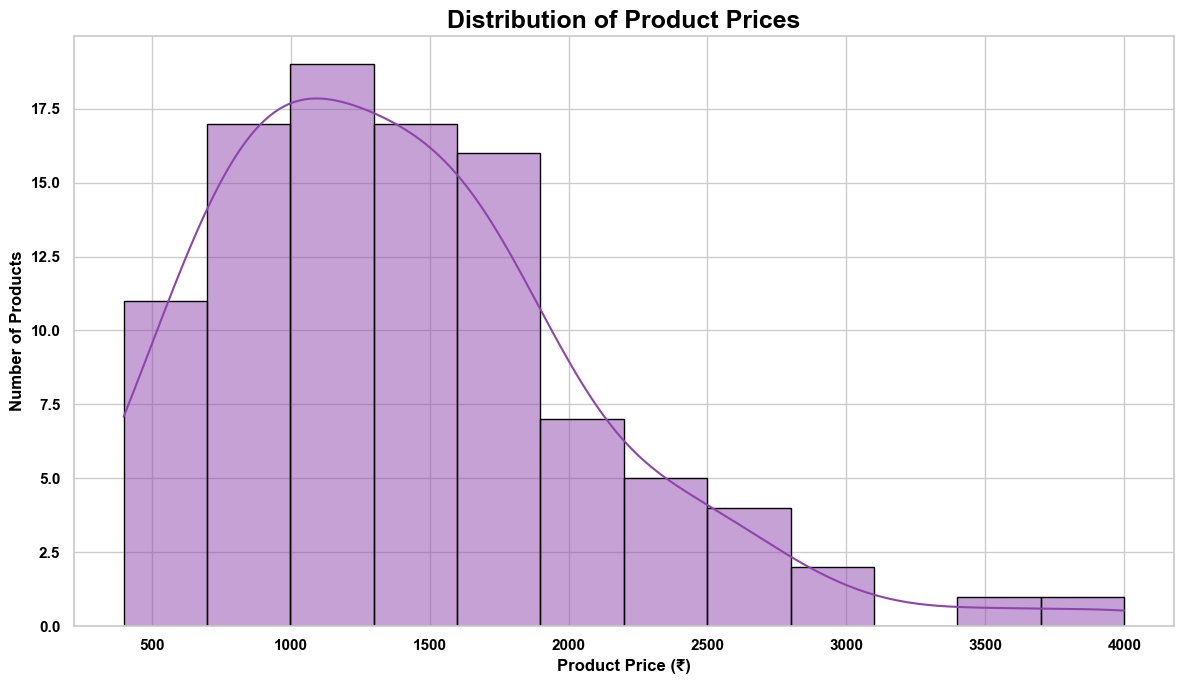

In [33]:

# histplot
 
query = """
SELECT Price
FROM Products
"""

cursor.execute(query)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df = pd.DataFrame(result, columns=columns)

plt.figure(figsize=(12, 7))
ax = sns.histplot(
    data=df, x="Price", bins=12,
    kde=True, color="#8E44AD", edgecolor="black"
)

ax.set_title("Distribution of Product Prices",
             fontsize=18, fontweight="bold", color="black")
ax.set_xlabel("Product Price (₹)", fontweight="bold", color="black")
ax.set_ylabel("Number of Products", fontweight="bold", color="black")

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")
    tick.set_color("black")

plt.tight_layout()
plt.show()


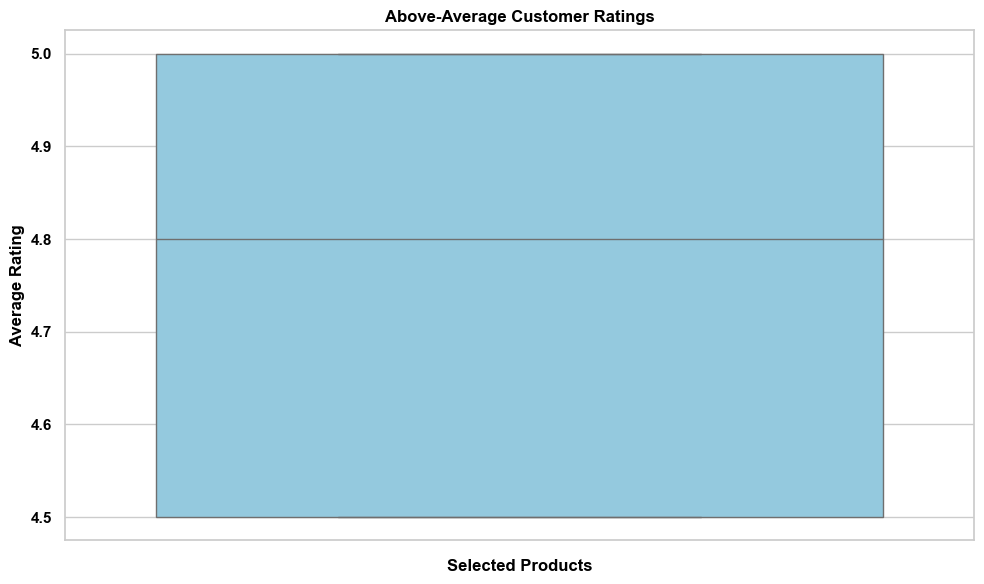

In [ ]:
# SUBQUERY —  Products with above-average ratings

query = """
SELECT p.Product_Name,
       AVG(s.Customer_Rating) AS Avg_Rating
FROM Products p
JOIN Sales s ON p.Product_ID = s.Product_ID
GROUP BY p.Product_ID, p.Product_Name
HAVING AVG(s.Customer_Rating) > (
    SELECT AVG(Customer_Rating)
    FROM Sales
)
"""

cursor.execute(query)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df = pd.DataFrame(result, columns=columns)

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, y="Avg_Rating", color="skyblue")
plt.title("Above-Average Customer Ratings", fontweight="bold", color="black")
plt.xlabel("Selected Products", fontweight="bold", color="black")
plt.ylabel("Average Rating", fontweight="bold", color="black")
plt.xticks(fontweight="bold", color="black")
plt.yticks(fontweight="bold", color="black")
plt.tight_layout()
plt.show()

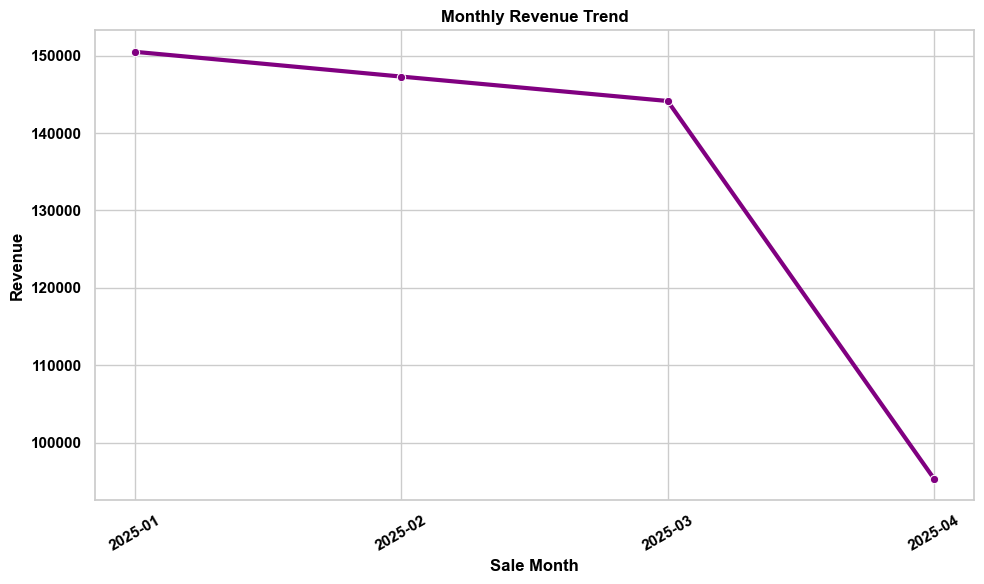

In [ ]:
# JOIN — Chart Monthly sales trend

query = """
SELECT DATE_FORMAT(s.Sale_Date, '%Y-%m') AS Sale_Month,
       SUM(s.Quantity_Sold * p.Price) AS Revenue
FROM Sales s
JOIN Products p ON s.Product_ID = p.Product_ID
GROUP BY DATE_FORMAT(s.Sale_Date, '%Y-%m')
ORDER BY Sale_Month
"""

cursor.execute(query)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df = pd.DataFrame(result, columns=columns)

plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x="Sale_Month", y="Revenue",
             marker="o", linewidth=3, color="purple")
plt.title("Monthly Revenue Trend", fontweight="bold", color="black")
plt.xlabel("Sale Month", fontweight="bold", color="black")
plt.ylabel("Revenue", fontweight="bold", color="black")
plt.xticks(rotation=30, fontweight="bold", color="black")
plt.yticks(fontweight="bold", color="black")
plt.tight_layout()
plt.show()

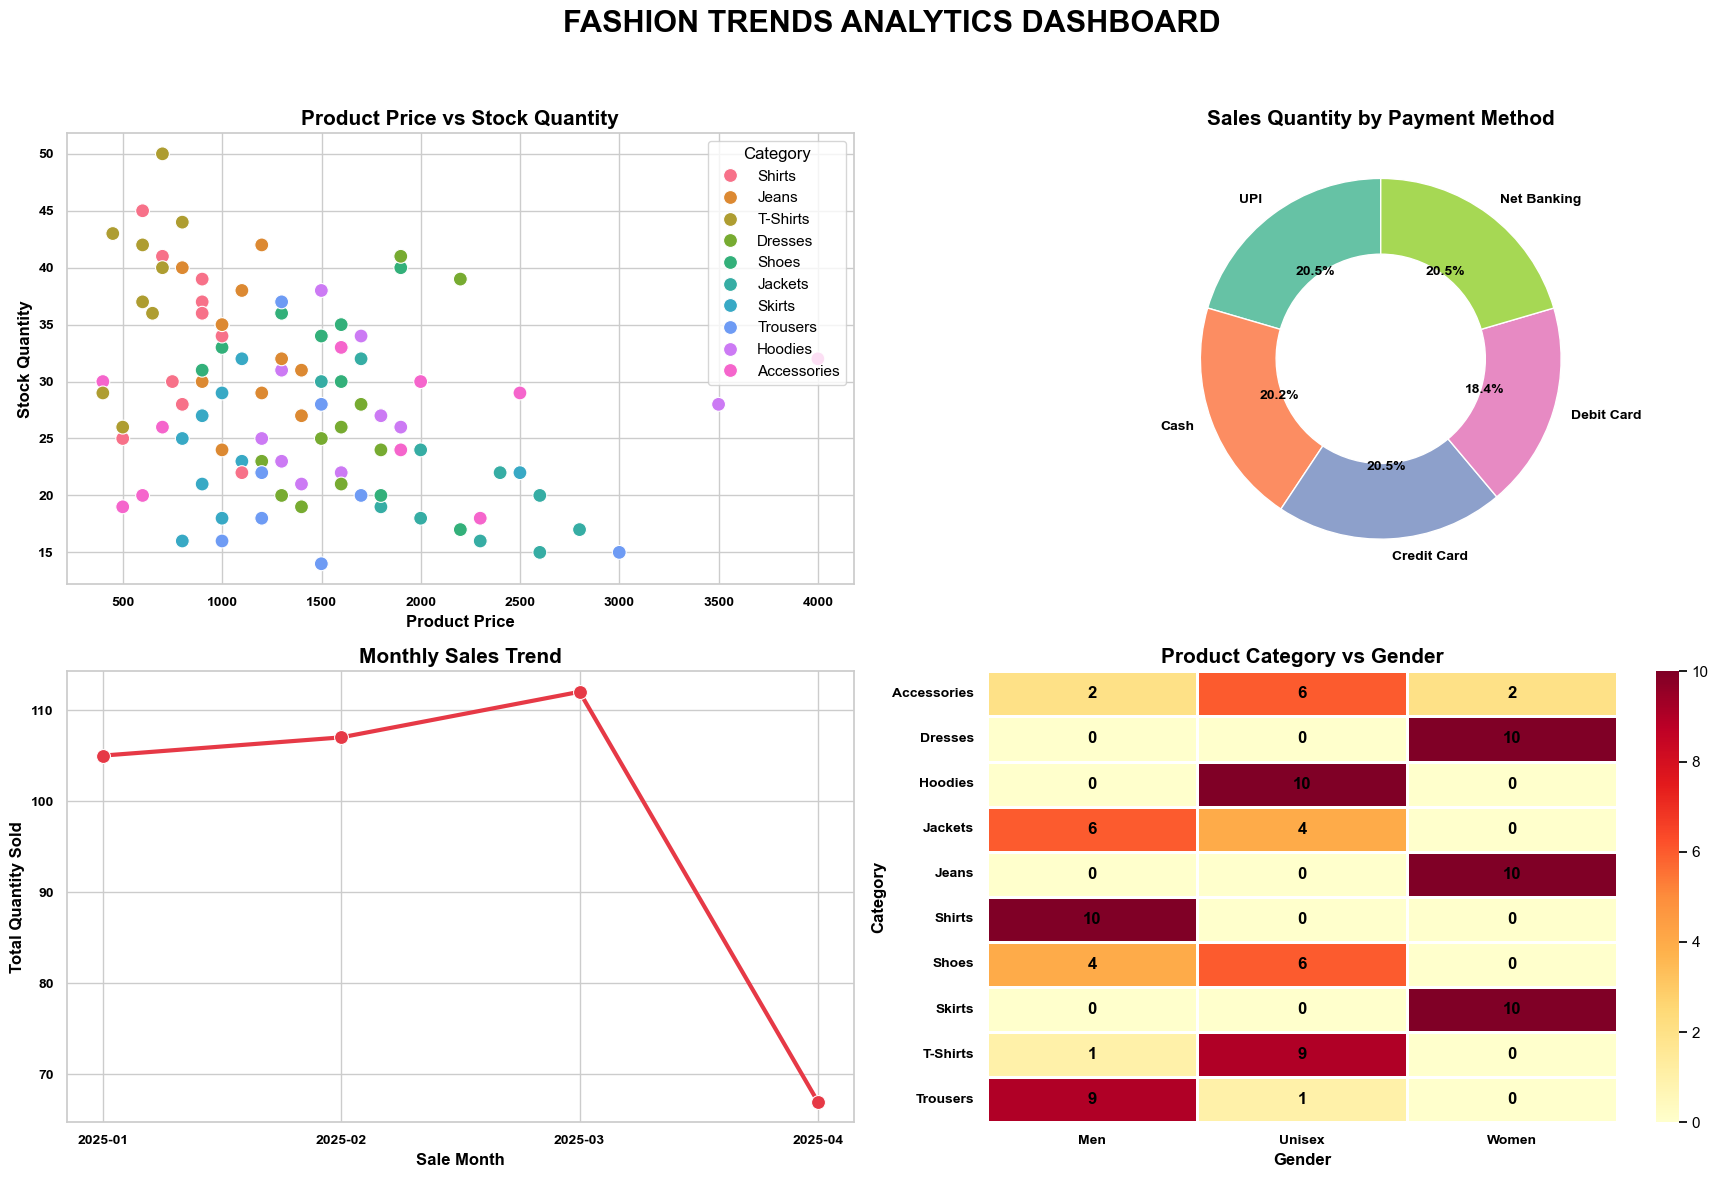

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dashboard style
sns.set_theme(style="whitegrid")
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["text.color"] = "black"
plt.rcParams["axes.labelcolor"] = "black"
plt.rcParams["xtick.color"] = "black"
plt.rcParams["ytick.color"] = "black"

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle(
    "FASHION TRENDS ANALYTICS DASHBOARD",
    fontsize=22, fontweight="bold", color="black"
)


# CHART 1: SCATTER PLOT - PRICE VS STOCK

query1 = """
SELECT Product_Name, Category, Price, Stock_Quantity
FROM Products
"""

cursor.execute(query1)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df1 = pd.DataFrame(result, columns=columns)

sns.scatterplot(
    data=df1,
    x="Price",
    y="Stock_Quantity",
    hue="Category",
    palette="husl",
    s=100,
    ax=axes[0, 0]
)

axes[0, 0].set_title(
    "Product Price vs Stock Quantity",
    fontsize=15, fontweight="bold", color="black"
)
axes[0, 0].set_xlabel("Product Price", fontweight="bold", color="black")
axes[0, 0].set_ylabel("Stock Quantity", fontweight="bold", color="black")
axes[0, 0].legend(title="Category")


# CHART 2: DONUT CHART - PAYMENT METHOD

query2 = """
SELECT Payment_Method, SUM(Quantity_Sold) AS Total_Quantity
FROM Sales
GROUP BY Payment_Method
"""

cursor.execute(query2)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df2 = pd.DataFrame(result, columns=columns)

axes[0, 1].pie(
    df2["Total_Quantity"],
    labels=df2["Payment_Method"],
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2", len(df2)),
    wedgeprops={"width": 0.42, "edgecolor": "white"},
    textprops={"color": "black", "weight": "bold", "fontsize": 10}
)

axes[0, 1].set_title(
    "Sales Quantity by Payment Method",
    fontsize=15, fontweight="bold", color="black"
)


# CHART 3: LINE CHART - MONTHLY SALES

query3 = """
SELECT DATE_FORMAT(Sale_Date, '%Y-%m') AS Sale_Month,
       SUM(Quantity_Sold) AS Total_Quantity
FROM Sales
GROUP BY DATE_FORMAT(Sale_Date, '%Y-%m')
ORDER BY Sale_Month
"""

cursor.execute(query3)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df3 = pd.DataFrame(result, columns=columns)

sns.lineplot(
    data=df3,
    x="Sale_Month",
    y="Total_Quantity",
    marker="o",
    markersize=10,
    linewidth=3,
    color="#E63946",
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    "Monthly Sales Trend",
    fontsize=15, fontweight="bold", color="black"
)
axes[1, 0].set_xlabel("Sale Month", fontweight="bold", color="black")
axes[1, 0].set_ylabel("Total Quantity Sold", fontweight="bold", color="black")


# CHART 4: HEATMAP - CATEGORY VS GENDER

query4 = """
SELECT Category, Gender, COUNT(*) AS Product_Count
FROM Products
GROUP BY Category, Gender
"""

cursor.execute(query4)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df4 = pd.DataFrame(result, columns=columns)

heatmap_data = df4.pivot(
    index="Category",
    columns="Gender",
    values="Product_Count"
).fillna(0)

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=1,
    linecolor="white",
    annot_kws={"weight": "bold", "color": "black"},
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "Product Category vs Gender",
    fontsize=15, fontweight="bold", color="black"
)
axes[1, 1].set_xlabel("Gender", fontweight="bold", color="black")
axes[1, 1].set_ylabel("Category", fontweight="bold", color="black")


# FINAL DASHBOARD FORMATTING

for ax in axes.flat:
    ax.tick_params(axis="both", labelsize=10)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")
        label.set_color("black")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


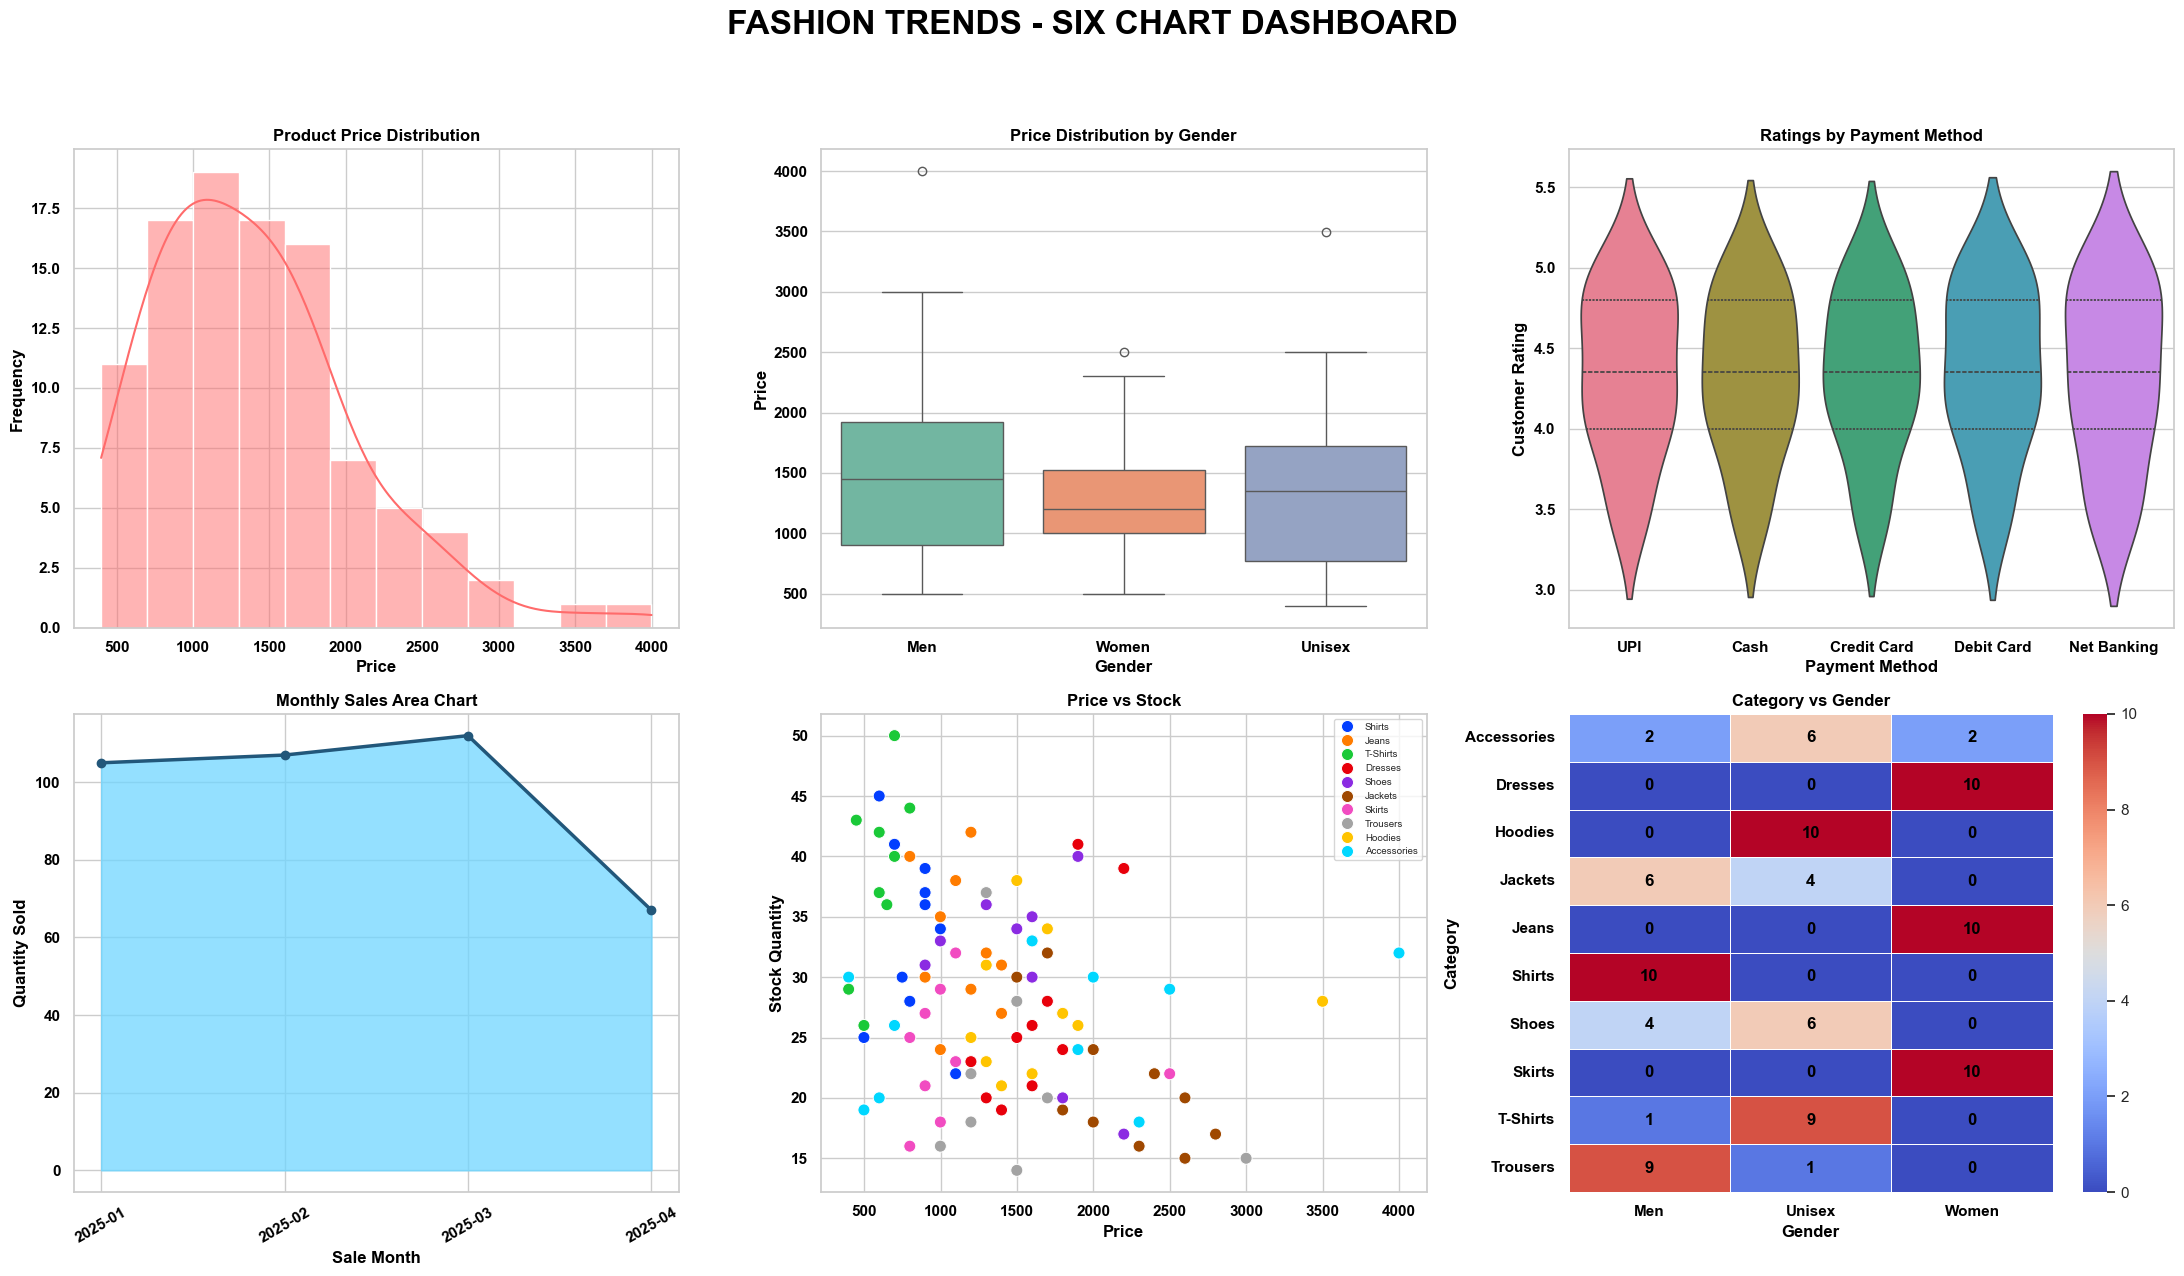

In [28]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"

fig, axes = plt.subplots(2, 3, figsize=(22, 13))
fig.suptitle(
    "FASHION TRENDS - SIX CHART DASHBOARD",
    fontsize=24, fontweight="bold", color="black"
)

# 1. HISTOGRAM - PRICE DISTRIBUTION
query1 = """
SELECT Price FROM Products
"""

cursor.execute(query1)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df1 = pd.DataFrame(result, columns=columns)

sns.histplot(
    data=df1, x="Price", bins=12,
    kde=True, color="#FF6B6B", ax=axes[0, 0]
)
axes[0, 0].set_title("Product Price Distribution", color="black")
axes[0, 0].set_xlabel("Price", color="black")
axes[0, 0].set_ylabel("Frequency", color="black")

# 2. BOX PLOT - PRICE BY GENDER
query2 = """
SELECT Gender, Price FROM Products
"""

cursor.execute(query2)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df2 = pd.DataFrame(result, columns=columns)

sns.boxplot(
    data=df2, x="Gender", y="Price",
    hue="Gender", palette="Set2",
    legend=False, ax=axes[0, 1]
)
axes[0, 1].set_title("Price Distribution by Gender", color="black")
axes[0, 1].set_xlabel("Gender", color="black")
axes[0, 1].set_ylabel("Price", color="black")

# 3. VIOLIN PLOT - CUSTOMER RATINGS
query3 = """
SELECT Payment_Method, Customer_Rating
FROM Sales
WHERE Customer_Rating IS NOT NULL
"""

cursor.execute(query3)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df3 = pd.DataFrame(result, columns=columns)

sns.violinplot(
    data=df3, x="Payment_Method", y="Customer_Rating",
    hue="Payment_Method", palette="husl",
    legend=False, inner="quartile", ax=axes[0, 2]
)
axes[0, 2].set_title("Ratings by Payment Method", color="black")
axes[0, 2].set_xlabel("Payment Method", color="black")
axes[0, 2].set_ylabel("Customer Rating", color="black")

# 4. AREA CHART - MONTHLY SALES
query4 = """
SELECT DATE_FORMAT(Sale_Date, '%Y-%m') AS Sale_Month,
       SUM(Quantity_Sold) AS Total_Quantity
FROM Sales
GROUP BY DATE_FORMAT(Sale_Date, '%Y-%m')
ORDER BY Sale_Month
"""

cursor.execute(query4)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df4 = pd.DataFrame(result, columns=columns)

axes[1, 0].fill_between(
    range(len(df4)), df4["Total_Quantity"],
    color="#70D6FF", alpha=0.75
)
axes[1, 0].plot(
    range(len(df4)), df4["Total_Quantity"],
    marker="o", color="#22577A", linewidth=2.5
)
axes[1, 0].set_xticks(range(len(df4)))
axes[1, 0].set_xticklabels(df4["Sale_Month"], rotation=30)
axes[1, 0].set_title("Monthly Sales Area Chart", color="black")
axes[1, 0].set_xlabel("Sale Month", color="black")
axes[1, 0].set_ylabel("Quantity Sold", color="black")

# 5. SCATTER PLOT - PRICE VS STOCK
query5 = """
SELECT Price, Stock_Quantity, Category
FROM Products
"""

cursor.execute(query5)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df5 = pd.DataFrame(result, columns=columns)

sns.scatterplot(
    data=df5, x="Price", y="Stock_Quantity",
    hue="Category", palette="bright",
    s=75, ax=axes[1, 1]
)
axes[1, 1].set_title("Price vs Stock", color="black")
axes[1, 1].set_xlabel("Price", color="black")
axes[1, 1].set_ylabel("Stock Quantity", color="black")
axes[1, 1].legend(fontsize=7)

# 6. HEATMAP - CATEGORY VS GENDER
query6 = """
SELECT Category, Gender, COUNT(*) AS Product_Count
FROM Products
GROUP BY Category, Gender
"""

cursor.execute(query6)
result = cursor.fetchall()
columns = [col[0] for col in cursor.description]
df6 = pd.DataFrame(result, columns=columns)

heatmap_data = df6.pivot(
    index="Category", columns="Gender",
    values="Product_Count"
).fillna(0)

sns.heatmap(
    heatmap_data, annot=True, fmt=".0f",
    cmap="coolwarm", linewidths=0.5,
    annot_kws={"weight": "bold", "color": "black"},
    ax=axes[1, 2]
)
axes[1, 2].set_title("Category vs Gender", color="black")
axes[1, 2].set_xlabel("Gender", color="black")
axes[1, 2].set_ylabel("Category", color="black")

# BOLD BLACK AXIS LABELS AND TICKS
for ax in axes.flat:
    ax.title.set_fontweight("bold")
    ax.title.set_color("black")
    ax.xaxis.label.set_fontweight("bold")
    ax.yaxis.label.set_fontweight("bold")
    ax.xaxis.label.set_color("black")
    ax.yaxis.label.set_color("black")
    ax.tick_params(axis="both", labelcolor="black")
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")
        label.set_color("black")

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()
